# Active life: from the first dated work or position to the last
Same logic as 02_works_periods, with positions held added: the active life starts at the earliest of the first dated work and the start of the first position held, and ends at the latest of the last dated work and the end of the last position held. Nothing is saved.

In [1]:
import json
import re
import sys
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
OUTPUT_PATH = Path('../../data/enriched_parquets/individual_active_life.parquet')  # datamodel shape
SAVE = True  # True writes OUTPUT_PATH
POSITIONS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the decade or better; coarser dates (century, millennium) are left out
DECADE_PRECISION = 8  # raw Wikidata precision: 8 decade, 9 year, 10 month, 11 day
MID_DECADE = 5  # a decade counts as its middle year
LIFETIME = 100  # years: the longest span of a single life
OCCUPATIONS = list(OCCUPATION_COLORS)  # the four occupational categories
ALL = 'All'  # no recorded occupation: the cohort of everyone
GROUPS = [*OCCUPATIONS, ALL]
MEASURES = ['start', 'end']
AGES = ['age_at_start', 'age_at_end']
AGE_RANGE = (10, 100)  # plausible ages at the start and the end of the active life, in years
LAST_BIRTH_YEAR = 1950  # born later: may still be active, neither learnt from nor imputed
MIN_COHORT = 10  # a smaller cohort takes the nearest century
CENTURY = 100  # years
TEST_SHARE = 0.2  # held-out share of the individuals with an active life
WITHIN = 10  # years between the imputed and the true year
GROUPINGS = {'overall': [], 'by century of birth': ['century'], 'by occupation': ['occupation'], 'by century of birth × occupation': ['century', 'occupation']}
STATISTICS = ['median', 'mean']  # the cohort's typical age
MODELS = {f'{statistic} {grouping}': (keys, statistic) for statistic in STATISTICS for grouping, keys in GROUPINGS.items()}
OVERALL = 'Overall'  # every individual, whatever the occupation
SPLIT_YEAR = 1500  # births before and after, in the second active-life figure
EXAMPLES = 12  # individuals with a birth and a death year shown with a predicted active life
MIN_SITELINKS = 20  # the examples are drawn among individuals with at least this many Wikipedia pages
SEED = 42

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Birth and death years from Wikidata only (no estimated date), precise to the year or the decade.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH held AS (
        SELECT entity.qid AS qid, unnest(occupation).entity.qid AS occupation_qid, generate_subscripts(occupation, 1) AS position
        FROM individual
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation AS occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN occupation ON occupation.entity.qid = held.occupation_qid
        WHERE list_contains($occupations, occupation.meta_occupation)
        GROUP BY ALL
    ),
    main_occupation AS (
        SELECT qid, occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ),
    dates AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS birth_year,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS death_year,
               coalesce(entity.label_en, entity.label_non_en) AS name,
               len(sitelink) AS sitelinks
        FROM individual
    )
    SELECT dates.qid, dates.name, dates.sitelinks,
           coalesce(main_occupation.occupation, $all) AS occupation,
           dates.birth_year, dates.death_year
    FROM dates
    LEFT JOIN main_occupation ON main_occupation.qid = dates.qid
''', params={'known': KNOWN_PRECISIONS, 'occupations': OCCUPATIONS, 'all': ALL}).pl()
death_caps = con.sql('''
    SELECT entity.qid AS qid,
           death_date.year AS death_cap,  -- Wikidata or estimated (01_age_at_death)
           CASE WHEN birth_date.source = 'estimated' THEN birth_date.year END AS estimated_birth_year  -- 01_age_at_death, Wikidata death only
    FROM individual_enriched
''').pl()
people = people.join(death_caps, on='qid', how='left')
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals')
people.sample(5, seed=SEED)

13,002,897 individuals


qid,name,sitelinks,occupation,birth_year,death_year,death_cap,estimated_birth_year
str,str,i64,str,i64,i64,i64,i64
"""Q133895743""","""Charles-Louis Morand Métivier""",0,"""Discovery/Science""",null,null,null,null
"""Q123140497""","""Yevhenii Lisnychyi""",1,"""Culture""",1997,null,null,null
"""Q91964674""","""Rediet Takele Regasa""",0,"""Discovery/Science""",null,null,null,null
"""Q7626164""","""Stu Harvey""",1,"""All""",null,null,null,null
"""Q95746452""","""Waltraud Wardegger""",0,"""Culture""",null,null,null,null


### Work dates
A work's date is its inception (P571), else its publication date (P577), precise to the year or the decade (a decade counting as its middle year).

In [3]:
con.register('lifetime', people.select('qid', 'birth_year', 'death_year').to_arrow())
work_dates = con.sql('''
    WITH dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               list_contains($known, work.inception.precision) AS from_inception,
               CASE WHEN list_contains($known, work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE list_contains($known, work.inception.precision) OR list_contains($known, work.publication_date.precision)
    )
    SELECT dated.qid, dated.work_qid,
           CASE WHEN dated.from_inception THEN 'inception' ELSE 'publication' END AS source,
           dated.date.year + CASE WHEN dated.date.precision = 'decade' THEN $mid_decade ELSE 0 END AS year,
           CASE WHEN dated.date.precision = 'decade' THEN 'decade' ELSE 'year' END AS precision,
           lifetime.birth_year, lifetime.death_year
    FROM dated
    JOIN lifetime ON lifetime.qid = dated.qid
''', params={'known': KNOWN_PRECISIONS, 'mid_decade': MID_DECADE}).pl()
con.close()
print(f'{work_dates.height:,} work dates for {work_dates["qid"].n_unique():,} individuals')
work_dates.sample(5, seed=SEED)

36,804,752 work dates for 2,773,370 individuals


qid,work_qid,source,year,precision,birth_year,death_year
str,str,str,i64,str,i64,i64
"""Q56480556""","""Q136306130""","""publication""",2022,"""year""",null,null
"""Q114289999""","""Q31126174""","""publication""",2013,"""year""",null,null
"""Q42642596""","""Q81695031""","""publication""",2005,"""year""",null,null
"""Q56493211""","""Q36102542""","""publication""",2011,"""year""",null,null
"""Q113092116""","""Q57008823""","""publication""",2014,"""year""",null,null


### Positions held
Raw Wikidata position held (P39) statements, deprecated ones dropped. A position's start (P580) and end (P582) each count on their own when precise to the year or the decade (a decade counting as its middle year): a position with a start only, or an end only, still dates the active life.

In [4]:
def dated_year(value):
    """The year of a start or end value precise to the decade or better, else None."""
    if not value or value['precision'] < DECADE_PRECISION:
        return None
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    year = -int(digits) if sign == '-' else int(digits)
    return year + (MID_DECADE if value['precision'] == DECADE_PRECISION else 0)


def precision(value):
    return None if not value or value['precision'] < DECADE_PRECISION else 'decade' if value['precision'] == DECADE_PRECISION else 'year'


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [{'qid': qid, 'position_qid': statement['target'],
      'start_year': dated_year(statement['start']), 'start_precision': precision(statement['start']),
      'end_year': dated_year(statement['end']), 'end_precision': precision(statement['end'])}
     for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.String, 'end_year': pl.Int64, 'end_precision': pl.String},
)
del raw
print(f"{positions.height:,} position statements for {positions['qid'].n_unique():,} individuals")
positions = positions.join(people.select('qid', 'birth_year', 'death_year'), on='qid')
print(f"{positions.height:,} statements for {positions['qid'].n_unique():,} individuals of the database")
positions.sample(5, seed=SEED)

1,947,131 position statements for 979,289 individuals


1,947,131 statements for 979,289 individuals of the database


qid,position_qid,start_year,start_precision,end_year,end_precision,birth_year,death_year
str,str,i64,str,i64,str,i64,i64
"""Q2723519""","""Q106090755""",1993,"""year""",1997,"""year""",1920,1997
"""Q17432272""","""Q21030356""",null,null,null,null,1922,1981
"""Q7192780""","""Q19305384""",1956,"""year""",1969,"""year""",1899,1982
"""Q11002029""","""Q140686""",2015,"""year""",null,null,1959,null
"""Q116932678""","""Q17486706""",null,null,null,null,null,null


## Cleaning
### Work dates (as in 02_works_periods)
1. Individuals without birth or death whose dated works carry only publication dates are excluded: a publication date may be a much later edition.
2. A work date must fall inside the lifetime: birth to death, or within 100 years of a single birth or death.
3. For individuals without birth or death, a publication date more than 100 years from their earliest inception is removed.
4. Individuals without birth or death whose inception dates alone span more than 100 years lose all their work dates.

In [5]:
has_lifetime = pl.col('birth_year').is_not_null() | pl.col('death_year').is_not_null()
inception_years = pl.col('year').filter(pl.col('source') == 'inception')
lower = pl.coalesce('birth_year', pl.col('death_year') - LIFETIME)
upper = pl.coalesce('death_year', pl.col('birth_year') + LIFETIME)
WORK_RULES = {
    '1. publication dates only, no birth or death': ~has_lifetime & inception_years.min().over('qid').is_null(),
    '2. outside the lifetime': ~pl.col('year').is_between(lower, upper),
    '3. publication over 100 years from the earliest inception': ~has_lifetime & (pl.col('source') == 'publication') & ((pl.col('year') - inception_years.min().over('qid')).abs() > LIFETIME),
    '4. inceptions spanning over 100 years': ~has_lifetime & ((inception_years.max() - inception_years.min()).over('qid') > LIFETIME),
}


def apply_rules(frame, rules, unit):
    """Apply the rules one after the other, logging the rows and the individuals left after each."""
    log = [{'step': 'start', unit: frame.height, 'individuals': frame['qid'].n_unique()}]
    for step, dropped in rules.items():
        frame = frame.filter(~dropped.fill_null(False))
        log.append({'step': step, unit: frame.height, 'individuals': frame['qid'].n_unique()})
    display(pl.DataFrame(log))
    return frame


kept_works = apply_rules(work_dates, WORK_RULES, 'work dates')

step,work dates,individuals
str,i64,i64
"""start""",36804752,2773370
"""1. publication dates only, no …",9637863,599887
"""2. outside the lifetime""",9479750,584832
"""3. publication over 100 years …",9478965,584832
"""4. inceptions spanning over 10…",9478728,584786


### Positions held
1. A position needs a start or an end (one is enough).
2. The end cannot come before the start.
3. Each start and end is then a position date, which must fall inside the lifetime (as for the works).
4. Individuals without birth or death whose position dates span more than 100 years lose all of them.

In [6]:
POSITION_RULES = {
    '1. no start and no end': pl.col('start_year').is_null() & pl.col('end_year').is_null(),
    '2. end before start': pl.col('end_year') < pl.col('start_year'),
}
DATE_RULES = {
    '3. outside the lifetime': ~pl.col('year').is_between(lower, upper),
    '4. position dates spanning over 100 years': ~has_lifetime & ((pl.col('year').max() - pl.col('year').min()).over('qid') > LIFETIME),
}
kept_positions = apply_rules(positions, POSITION_RULES, 'positions')
position_dates = pl.concat([
    kept_positions.select('qid', 'birth_year', 'death_year', pl.lit(f'position {end}').alias('kind'), pl.col(f'{end}_year').alias('year'), pl.col(f'{end}_precision').alias('precision'))
    for end in ('start', 'end')
]).drop_nulls('year')
kept_position_dates = apply_rules(position_dates, DATE_RULES, 'position dates')

step,positions,individuals
str,i64,i64
"""start""",1947131,979289
"""1. no start and no end""",1276638,574868
"""2. end before start""",1276296,574753


step,position dates,individuals
str,i64,i64
"""start""",2258908,574753
"""3. outside the lifetime""",2254925,574265
"""4. position dates spanning ove…",2254541,574224


## Active life
The start is the earliest dated event and the end the latest: a work, the start of a position or the end of a position. A position with a start only and a later work, for instance, make an active life. The ages are counted from the Wikidata birth year. Individuals without birth or death whose works and positions together span more than 100 years are dropped.

In [7]:
events = pl.concat([
    kept_works.select('qid', 'year', 'precision', pl.lit('work').alias('kind')),
    kept_position_dates.select('qid', 'year', 'precision', 'kind'),
])
active = (
    events.group_by('qid')
    .agg(
        pl.col('year').min().alias('start_year'),
        pl.col('year').max().alias('end_year'),
        pl.col('kind').sort_by('year', 'kind').first().alias('start_source'),
        pl.col('kind').sort_by('year', 'kind').last().alias('end_source'),
        pl.col('precision').sort_by('year', pl.col('precision') == 'decade').first().alias('start_precision'),
        pl.col('precision').sort_by('year', pl.col('precision') == 'year').last().alias('end_precision'),
        (pl.col('kind') == 'work').any().alias('has_work'),
        (pl.col('kind') != 'work').any().alias('has_position'),
    )
    .join(people, on='qid')
)
print(f'{active.height:,} individuals with dated works or positions')
active = active.filter(has_lifetime | (pl.col('end_year') - pl.col('start_year') <= LIFETIME))
print(f'{active.height:,} after dropping those with no birth or death spanning over {LIFETIME} years')
active = active.with_columns(
    (pl.col('start_year') - pl.col('birth_year')).alias('age_at_start'),
    (pl.col('end_year') - pl.col('birth_year')).alias('age_at_end'),
    (pl.col('birth_year') // CENTURY * CENTURY).alias('century'),
)
assert active['qid'].is_unique().all() and (active['start_year'] <= active['end_year']).all()
active.sample(5, seed=SEED)

1,133,997 individuals with dated works or positions
1,133,994 after dropping those with no birth or death spanning over 100 years


qid,start_year,end_year,start_source,end_source,start_precision,end_precision,has_work,has_position,name,sitelinks,occupation,birth_year,death_year,death_cap,estimated_birth_year,age_at_start,age_at_end,century
str,i64,i64,str,str,str,str,bool,bool,str,i64,str,i64,i64,i64,i64,i64,i64,i64
"""Q121784034""",1836,1836,"""work""","""work""","""year""","""year""",true,false,"""Pierre Yperman""",0,"""Culture""",null,null,null,null,null,null,null
"""Q65583722""",2014,2025,"""position start""","""position end""","""year""","""year""",false,true,"""Alain Goirot""",0,"""Leadership""",1966,null,null,null,48,59,1900
"""Q26180322""",1999,1999,"""work""","""work""","""year""","""year""",true,false,"""Mary Cannell""",2,"""Culture""",1913,2000,2000,null,86,86,1900
"""Q6913369""",1999,2000,"""work""","""work""","""year""","""year""",true,false,"""Morphem""",0,"""Culture""",1998,null,null,null,1,2,1900
"""Q16204629""",2008,2018,"""work""","""work""","""year""","""year""",true,false,"""Rebecca Makkai""",15,"""Culture""",1978,null,null,null,30,40,1900


## Age at the start and the end of the active life
Learnt from the individuals with a Wikidata birth year up to 1950 whose active life starts and ends between the ages of 10 and 100, in different years. Each value is the median age in every century of birth with at least 10 individuals, averaged over those centuries (each century weighs the same). Overall covers every individual, with an occupation or not.

In [8]:
lives = active.filter(
    (pl.col('birth_year') <= LAST_BIRTH_YEAR)
    & pl.col('age_at_start').is_between(*AGE_RANGE)
    & pl.col('age_at_end').is_between(*AGE_RANGE)
)
print(f'{lives.height:,} of {active.height:,} active lives')
lives = lives.filter(pl.col('start_year') < pl.col('end_year'))
print(f'{lives.height:,} with the start and the end in different years')

555,912 of 1,133,994 active lives
404,674 with the start and the end in different years


### What the active lives are made of
How many come from works only, positions only or both, and which kind of date sets the start and the end.

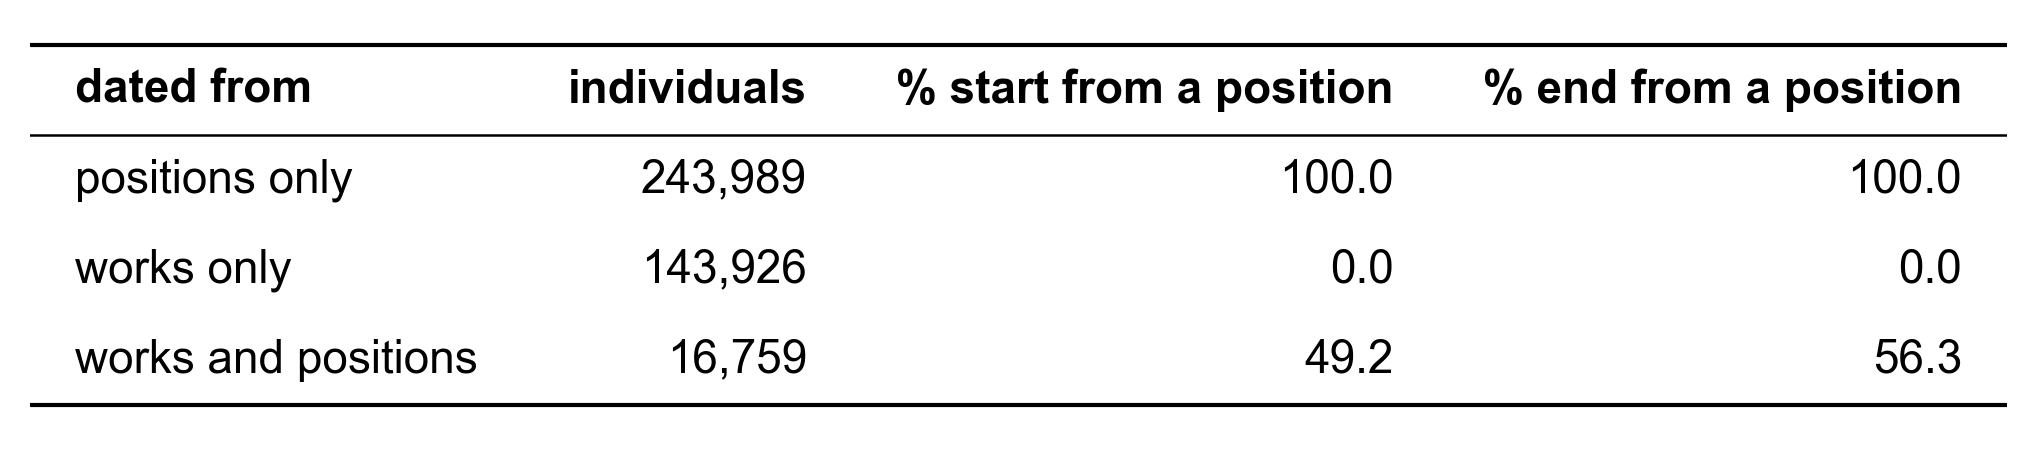

In [9]:
made_of = lives.with_columns(
    pl.when(pl.col('has_work') & pl.col('has_position')).then(pl.lit('works and positions'))
    .when(pl.col('has_work')).then(pl.lit('works only'))
    .otherwise(pl.lit('positions only')).alias('dated from')
).group_by('dated from').agg(
    pl.len().alias('individuals'),
    (100 * (pl.col('start_source') != 'work').mean()).alias('% start from a position'),
    (100 * (pl.col('end_source') != 'work').mean()).alias('% end from a position'),
).sort('individuals', descending=True)
assert made_of['individuals'].sum() == lives.height
show_table(made_of, decimals=1)

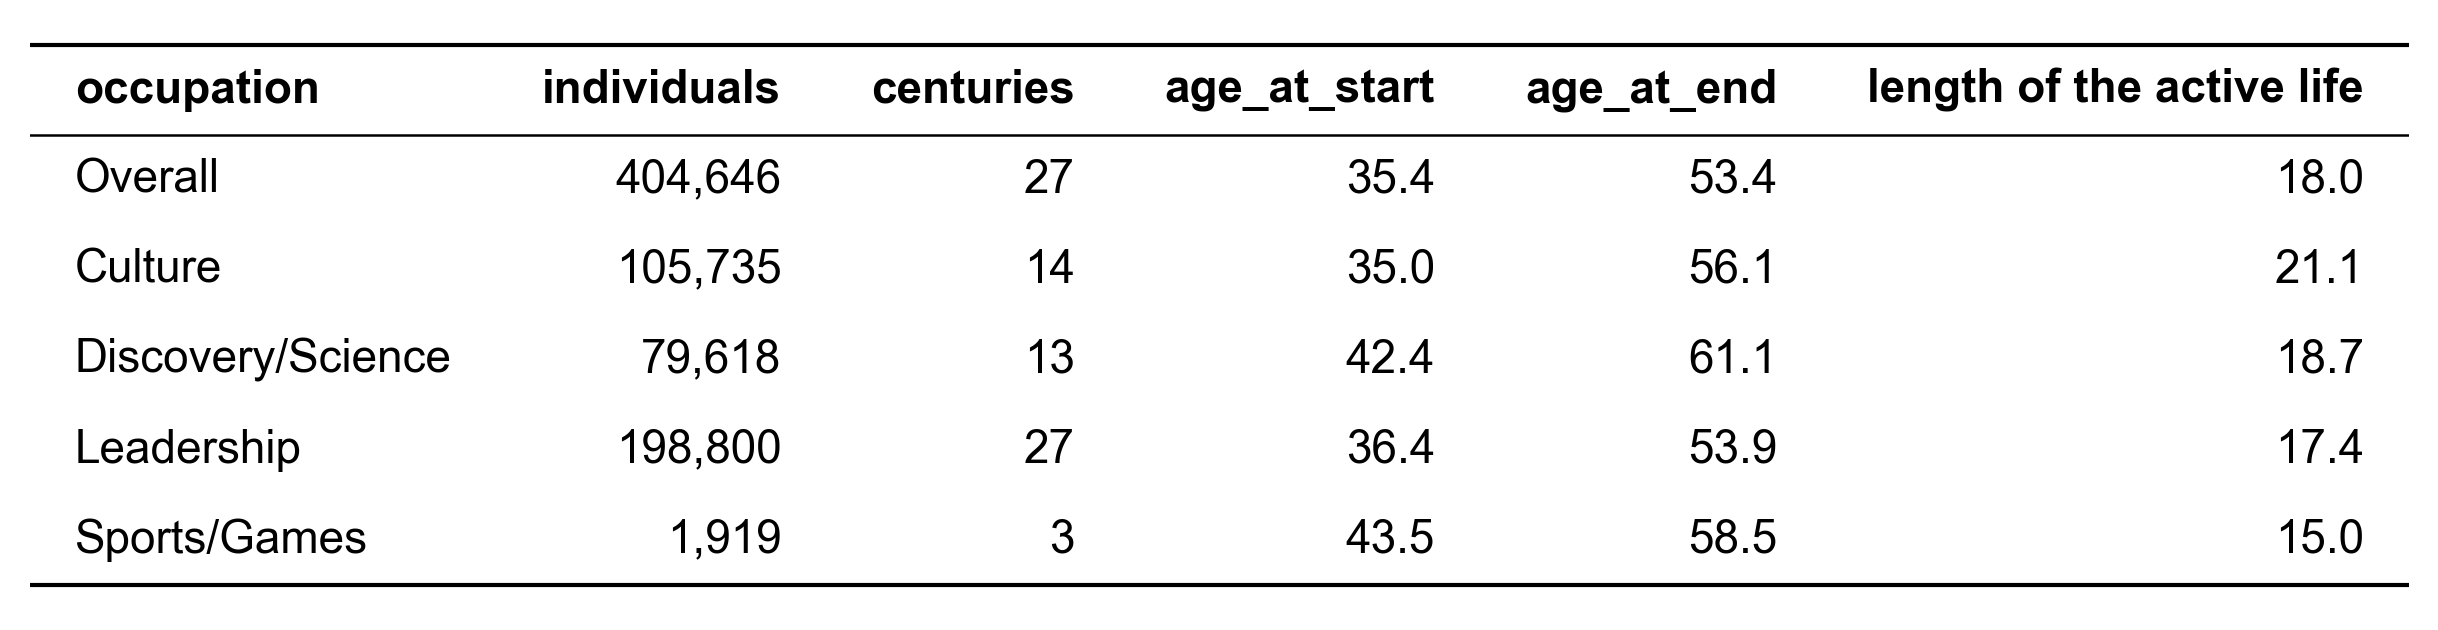

In [10]:
def century_average(frame, by, statistic='median'):
    """Median (or mean) ages in every century of birth with at least MIN_COHORT individuals, averaged over those centuries."""
    return (
        frame.group_by(*by, 'century').agg(pl.len().alias('individuals'), getattr(pl.col(AGES), statistic)())
        .filter(pl.col('individuals') >= MIN_COHORT)
        .group_by(by).agg(pl.col('individuals').sum(), pl.len().alias('centuries'), pl.col(AGES).mean())
    )


def spans(frame):
    """Century-averaged ages at the start and the end: overall (every individual) and for each of the four occupations."""
    return pl.concat([
        century_average(frame.with_columns(pl.lit(OVERALL).alias('occupation')), ['occupation']),
        century_average(frame.filter(pl.col('occupation') != ALL), ['occupation']),
    ]).sort(pl.col('occupation').replace_strict([OVERALL, *OCCUPATIONS], list(range(len(OCCUPATIONS) + 1))))


show_table(spans(lives).with_columns((pl.col('age_at_end') - pl.col('age_at_start')).alias('length of the active life')), decimals=1)

### Active life, overall and by occupation
Century-averaged age at the start and at the end of the active life; above, its length. Overall covers every individual, with an occupation or not.

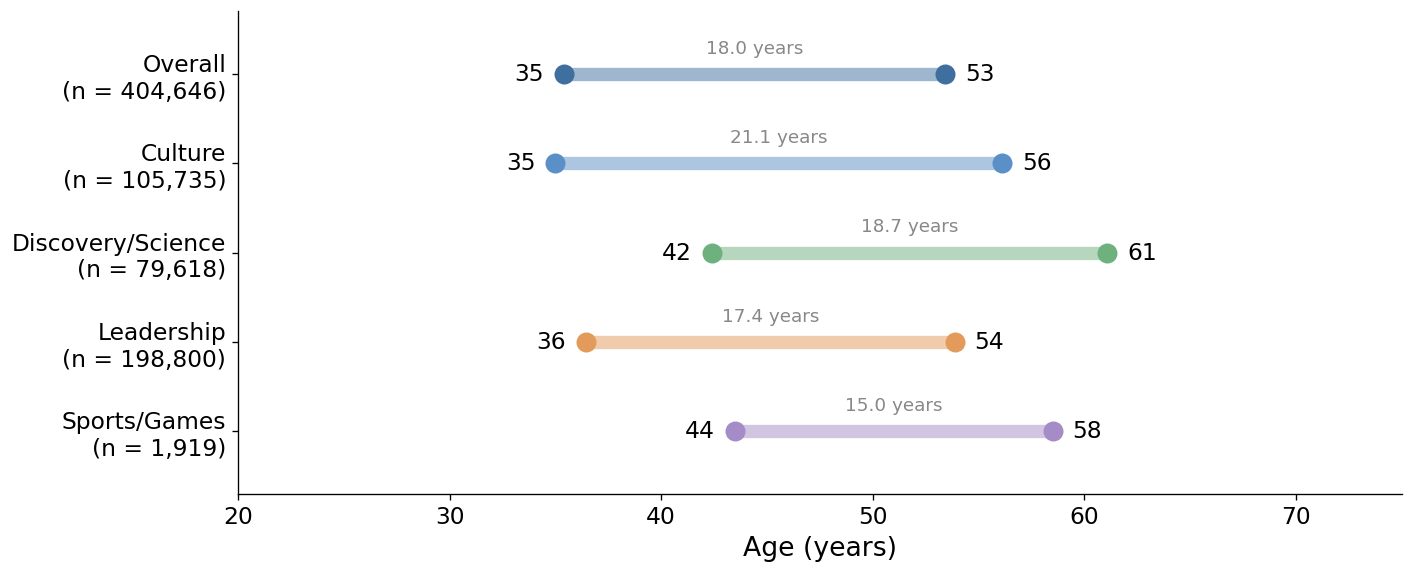

In [11]:
ROW_ORDER = [OVERALL, *OCCUPATIONS]
ROW_COLORS = {OVERALL: MAIN_LINE_COLOR, **OCCUPATION_COLORS}


def draw_span(ax, y, row, color, side=1, hollow=False, show_n=False):
    start, end = row['age_at_start'], row['age_at_end']
    ax.plot([start, end], [y, y], color=color, linewidth=8, solid_capstyle='round', alpha=0.25 if hollow else 0.5)
    ax.plot([start, end], [y, y], 'o', color=color, markersize=10, markeredgewidth=2, markerfacecolor='white' if hollow else color)
    ax.annotate(f'{start:.0f}', (start, y), xytext=(-12, 0), textcoords='offset points', ha='right', va='center')
    ax.annotate(f'{end:.0f}', (end, y), xytext=(12, 0), textcoords='offset points', ha='left', va='center')
    length = f"{end - start:.1f} years" + (f" (n = {row['individuals']:,})" if show_n else '')
    ax.annotate(length, ((start + end) / 2, y), xytext=(0, 10 * side), textcoords='offset points', ha='center',
                va='bottom' if side > 0 else 'top', color=MUTED_TEXT, fontsize=POINT_LABEL_FONTSIZE)


def finish(ax, labels):
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels[::-1])
    ax.set_ylim(-0.7, len(labels) - 0.3)
    ax.set_xlim(20, 75)
    ax.set_xlabel('Age (years)')
    ax.grid(axis='y', visible=False)
    plt.tight_layout()
    plt.show()


everyone = {row['occupation']: row for row in spans(lives).iter_rows(named=True)}
rows = [group for group in ROW_ORDER if group in everyone]
fig, ax = plt.subplots(figsize=FIGSIZE)
for i, group in enumerate(rows):
    draw_span(ax, len(rows) - 1 - i, everyone[group], ROW_COLORS[group])
finish(ax, [f"{group}\n(n = {everyone[group]['individuals']:,})" for group in rows])

### Active life, born before and after 1500
Hollow: born before 1500; filled: born from 1500 to 1950. Century-averaged as above.

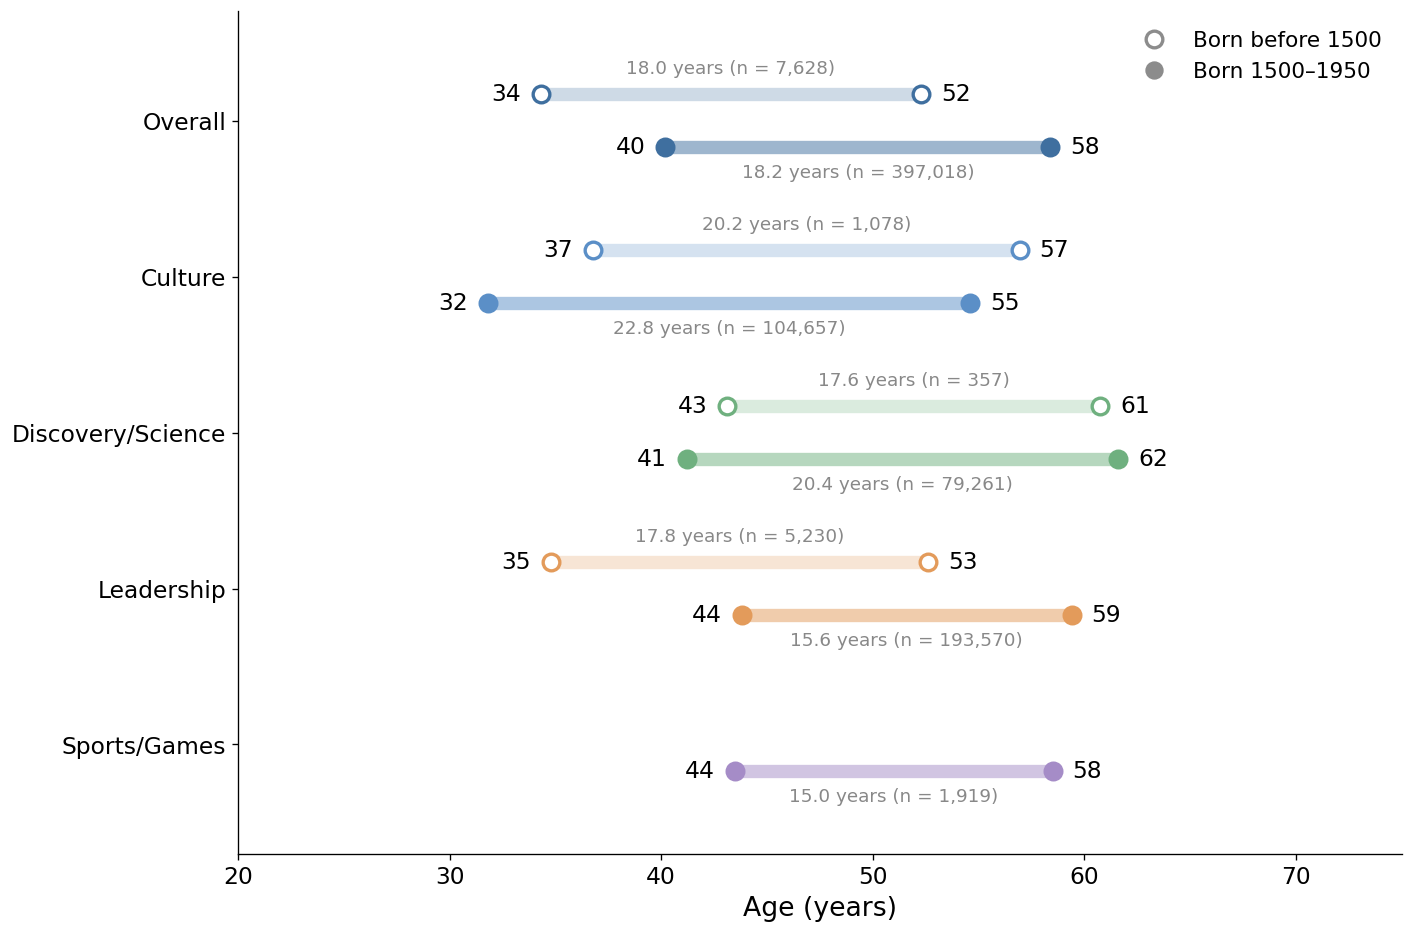

In [12]:
before = {row['occupation']: row for row in spans(lives.filter(pl.col('birth_year') < SPLIT_YEAR)).iter_rows(named=True)}
after = {row['occupation']: row for row in spans(lives.filter(pl.col('birth_year') >= SPLIT_YEAR)).iter_rows(named=True)}
fig, ax = plt.subplots(figsize=(12, 8))
for i, group in enumerate(rows):
    y = len(rows) - 1 - i
    if group in before:
        draw_span(ax, y + 0.17, before[group], ROW_COLORS[group], side=1, hollow=True, show_n=True)
    if group in after:
        draw_span(ax, y - 0.17, after[group], ROW_COLORS[group], side=-1, show_n=True)
ax.plot([], [], 'o', color=GREY, markerfacecolor='white', markeredgewidth=2, markersize=10, label=f'Born before {SPLIT_YEAR}')
ax.plot([], [], 'o', color=GREY, markersize=10, label=f'Born {SPLIT_YEAR}–{LAST_BIRTH_YEAR}')
ax.legend(loc='upper right')
finish(ax, rows)

## Models
Each model imputes the year as birth year + the median (or the mean) age at the start (or the end) of the active life of the individual's cohort: everyone (overall), the same century of birth, the same occupation, or both. Individuals with no occupation take the cohort of everyone. The overall and occupation values are the century medians (or means) averaged over the centuries of birth with at least 10 individuals; a century cohort with fewer than 10 individuals takes the nearest century. The end is capped at the death year (from Wikidata, else estimated in 01_age_at_death) and the start at the end.

In [13]:
first_century = people['birth_year'].min() // CENTURY * CENTURY
grid = pl.DataFrame({'century': range(first_century, LAST_BIRTH_YEAR // CENTURY * CENTURY + 1, CENTURY)}).join(pl.DataFrame({'occupation': GROUPS}), how='cross')


def cohort_table(lives, measure, model):
    """Median (or mean) age at the start or the end of the model's cohort, for every century of birth and occupation."""
    keys, statistic = MODELS[model]
    if 'occupation' in keys:
        lives = pl.concat([lives.filter(pl.col('occupation') != ALL), lives.with_columns(pl.lit(ALL).alias('occupation'))])
    if 'century' not in keys:
        everyone = lives.with_columns(pl.lit(OVERALL).alias('everyone'))
        cohorts = century_average(everyone, keys or ['everyone'], statistic).select(*keys, pl.col('individuals').alias('cohort_individuals'), pl.col(f'age_at_{measure}').alias('age'))
        table = (grid.join(cohorts, on=keys) if keys else grid.join(cohorts, how='cross')).with_columns(pl.col('century').alias('cohort_century'))
    else:
        cohorts = (
            lives.group_by(keys).agg(pl.len().alias('cohort_individuals'), getattr(pl.col(f'age_at_{measure}'), statistic)().alias('age'))
            .filter(pl.col('cohort_individuals') >= MIN_COHORT).rename({'century': 'cohort_century'})
        )
        others = [key for key in keys if key != 'century']
        table = (
            (grid.join(cohorts, on=others) if others else grid.join(cohorts, how='cross'))
            .sort((pl.col('cohort_century') - pl.col('century')).abs(), 'cohort_century', descending=[False, True])
            .group_by('occupation', 'century', maintain_order=True).first()
        )
    assert table.height == grid.height
    return table


def impute(targets, tables):
    """Start and end = birth year + the cohort's median age, the end no later than the death and the start no later than the end."""
    imputed = targets.select('qid', 'name', 'occupation', 'birth_year', 'death_year', 'death_cap', *[c for c in ('start_year', 'end_year') if c in targets.columns]).with_columns(
        (pl.col('birth_year') // CENTURY * CENTURY).clip(grid['century'].min(), grid['century'].max()).alias('century')
    )
    for measure, table in tables.items():
        imputed = imputed.join(
            table.select('occupation', 'century', *[pl.col(c).alias(f'{measure}_{c}') for c in ('cohort_century', 'cohort_individuals', 'age')]),
            on=['occupation', 'century'], how='left',
        ).with_columns((pl.col('birth_year') + pl.col(f'{measure}_age').round()).cast(pl.Int64).alias(f'{measure}_from_cohort'))
    imputed = imputed.with_columns(pl.min_horizontal('end_from_cohort', 'death_cap').alias('imputed_end_year'))
    imputed = imputed.with_columns(pl.min_horizontal('start_from_cohort', 'imputed_end_year').alias('imputed_start_year'))
    assert imputed.height == targets.height and imputed['imputed_start_year'].null_count() == imputed['imputed_end_year'].null_count() == 0
    return imputed

## Test on a held-out 20%
Each score is computed in every century of birth with at least 10 test individuals, then averaged over those centuries (each century weighs the same).

In [14]:
test = lives.sort('qid').sample(fraction=TEST_SHARE, shuffle=True, seed=SEED)
train = lives.join(test, on='qid', how='anti')
assert train.height + test.height == lives.height
print(f'train: {train.height:,}, test: {test.height:,}')

scores = []
for model in MODELS:
    imputed_test = impute(test, {measure: cohort_table(train, measure, model) for measure in MEASURES})
    row = {'model': model}
    for measure in MEASURES:
        per_century = (
            imputed_test.with_columns((pl.col(f'imputed_{measure}_year') - pl.col(f'{measure}_year')).abs().alias('error'))
            .group_by('century')
            .agg(pl.len().alias('individuals'), pl.col('error').mean().alias('error'), (100 * (pl.col('error') <= WITHIN).mean()).alias('within'))
            .filter(pl.col('individuals') >= MIN_COHORT)
        )
        row[f'{measure}: mean absolute error'] = per_century['error'].mean()
        row[f'{measure}: % within {WITHIN} years'] = per_century['within'].mean()
    scores.append(row)
scores = pl.DataFrame(scores)
median_scores = scores.filter(pl.col('model').str.starts_with('median'))
BEST = {measure: median_scores.sort(f'{measure}: % within {WITHIN} years', descending=True)['model'][0] for measure in MEASURES}
print(f"best model, start of the active life: {BEST['start']}; end: {BEST['end']}")

train: 323,740, test: 80,934


best model, start of the active life: median by century of birth × occupation; end: median by century of birth × occupation


### % of the held-out 20% imputed within 10 years, median models [mean absolute error, in years], averaged over centuries of birth

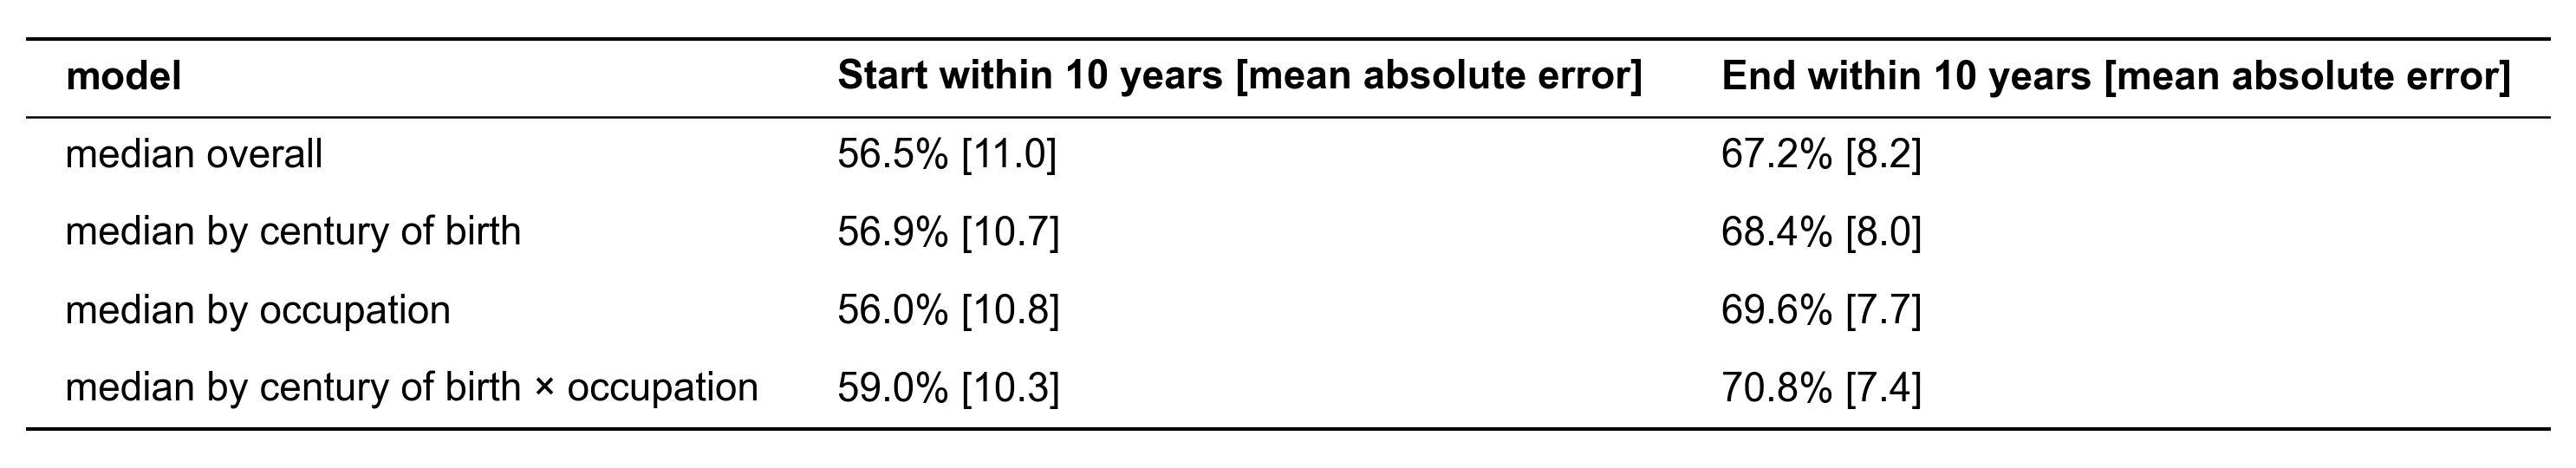

In [15]:
show_table(median_scores.select('model', *[
    pl.format('{}% [{}]', pl.col(f'{measure}: % within {WITHIN} years').round(1), pl.col(f'{measure}: mean absolute error').round(1))
    .alias(f'{measure.capitalize()} within {WITHIN} years [mean absolute error]')
    for measure in MEASURES
]))

## Predicted active life of individuals with a birth and a death year
Random individuals with a Wikidata birth (up to 1950) and death year, at least 20 Wikipedia pages and no active life (no dated work or position, or all in a single year). Each end uses its best model, learnt on all the active lives; the cohort is the group the age comes from.

17,505 candidates


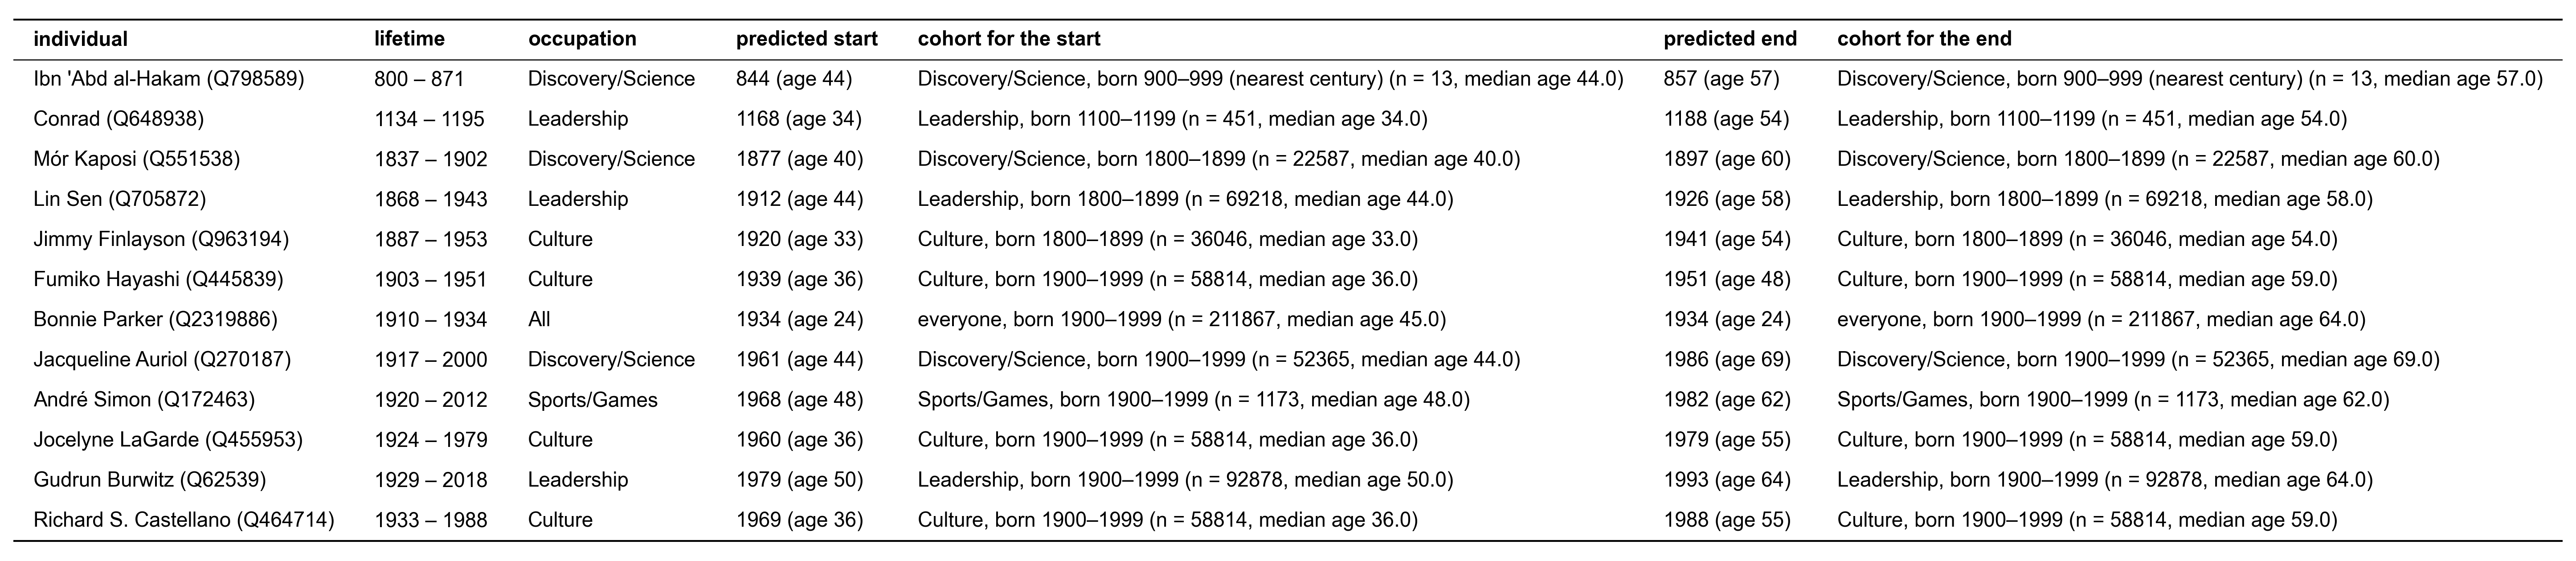

In [16]:
def cohort_text(measure):
    """The cohort the model took the age from: its occupation, its century of birth, its size and its median (or mean) age."""
    keys, statistic = MODELS[BEST[measure]]
    group = pl.lit('all occupations')
    if 'occupation' in keys:
        group = pl.when(pl.col('occupation') == ALL).then(pl.lit('everyone')).otherwise(pl.col('occupation'))
    born = pl.lit('all centuries')
    if 'century' in keys:
        born = pl.format('born {}–{}', f'{measure}_cohort_century', pl.col(f'{measure}_cohort_century') + CENTURY - 1)
        born = pl.when(pl.col(f'{measure}_cohort_century') != pl.col('century')).then(pl.format('{} (nearest century)', born)).otherwise(born)
    return pl.format(f'{{}}, {{}} (n = {{}}, {statistic} age {{}})', group, born, f'{measure}_cohort_individuals', pl.col(f'{measure}_age').round(1))


tables = {measure: cohort_table(lives, measure, BEST[measure]) for measure in MEASURES}
with_active_life = active.filter(pl.col('start_year') < pl.col('end_year'))
candidates = (
    people.filter(pl.col('birth_year').is_not_null() & pl.col('death_year').is_not_null() & (pl.col('birth_year') <= LAST_BIRTH_YEAR) & (pl.col('sitelinks') >= MIN_SITELINKS))
    .join(with_active_life, on='qid', how='anti')
)
print(f'{candidates.height:,} candidates')
examples = impute(candidates.sort('qid').sample(EXAMPLES, seed=SEED), tables).sort('birth_year')
show_table(examples.select(
    pl.format('{} ({})', 'name', 'qid').alias('individual'),
    pl.format('{} – {}', 'birth_year', 'death_year').alias('lifetime'),
    'occupation',
    pl.format('{} (age {})', 'imputed_start_year', pl.col('imputed_start_year') - pl.col('birth_year')).alias('predicted start'),
    cohort_text('start').alias('cohort for the start'),
    pl.format('{} (age {})', 'imputed_end_year', pl.col('imputed_end_year') - pl.col('birth_year')).alias('predicted end'),
    cohort_text('end').alias('cohort for the end'),
))

## Imputation for everyone without an active life
Individuals with no active life (no dated work or position, or all in a single year) and a birth year up to 1950: from Wikidata, else estimated from the age at death in 01_age_at_death (Wikidata death only). Individuals whose dated events fall in a single year and who have no birth year to estimate from keep that year.

In [17]:
single_year = active.filter(pl.col('start_year') == pl.col('end_year')).select('qid', pl.col('start_year').alias('single_year'))
targets = (
    people.join(with_active_life, on='qid', how='anti')
    .join(single_year, on='qid', how='left')
    .with_columns(pl.col('birth_year').is_null().alias('estimated_birth'), pl.coalesce('birth_year', 'estimated_birth_year').alias('birth_year'))
    .filter(pl.col('birth_year') <= LAST_BIRTH_YEAR)
)
imputed = impute(targets, tables).join(targets.select('qid', 'estimated_birth', 'single_year'), on='qid')
print(f'{imputed.height:,} individuals imputed ({imputed["estimated_birth"].sum():,} from an estimated birth)')

4,100,202 individuals imputed (275,188 from an estimated birth)


### Active lives reduced to nothing by the death
The cohort's age at the start falls on or after the death, so the start and the end are both capped at the death year: an active life of 0 years. Counted among the imputed individuals with a death year (Wikidata or estimated).

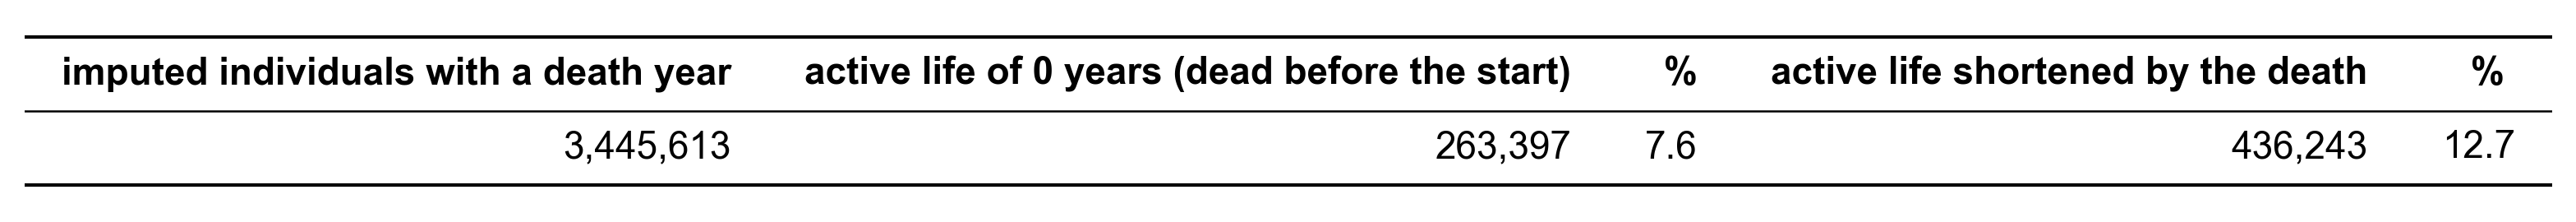

In [18]:
with_death = imputed.filter(pl.col('death_cap').is_not_null())
zero = with_death.filter(pl.col('start_from_cohort') >= pl.col('death_cap'))
shortened = with_death.filter((pl.col('end_from_cohort') > pl.col('death_cap')) & (pl.col('start_from_cohort') < pl.col('death_cap')))
assert (zero['imputed_start_year'] == zero['imputed_end_year']).all()
show_table(pl.DataFrame([
    {'imputed individuals with a death year': with_death.height,
     'active life of 0 years (dead before the start)': zero.height,
     '%': 100 * zero.height / with_death.height,
     'active life shortened by the death': shortened.height,
     '% ': 100 * shortened.height / with_death.height},
]), decimals=1)

## Save
One row per individual with `IndividualEnriched.start_of_active_life` and `end_of_active_life`: read from the dated works and positions (`source = 'dated works and positions'`) when they span more than one year, else imputed (`source = 'estimated'`, with the `cohort` used); `field_provenance` gives the rule.

In [19]:
sys.path.insert(0, '../../scripts/1-datamodels')
sys.path.insert(0, '../../scripts/3-raw_to_db/helpers')
import datamodel_in_duckdb as D
from pydantic_to_duckdb_schema import duck_type

DATE_TYPE = duck_type(D.IndividualDate)
INPUTS = ['Individual.work', 'Work.inception', 'Work.publication_date', 'Individual.position_held', 'Individual.birth_date', 'Individual.death_date', 'IndividualEnriched.birth_date', 'IndividualEnriched.death_date', 'Occupation.meta_occupation']
OBSERVED_RULE = (
    f'From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, '
    f'precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within {LIFETIME} years of a single birth or death), cleaned as in 03_b_active_life.'
)


def estimated_rule(measure):
    keys, statistic = MODELS[BEST[measure]]
    group = pl.when(pl.col('occupation') == ALL).then(pl.lit('individuals')).otherwise(pl.col('occupation') + ' individuals') if 'occupation' in keys else pl.lit('individuals')
    born = pl.format(' born in {}–{}', f'{measure}_cohort_century', pl.col(f'{measure}_cohort_century') + CENTURY - 1) if 'century' in keys else pl.lit('')
    cap = 'the death year' if measure == 'end' else 'the estimated end'
    capped = pl.when(pl.col(f'imputed_{measure}_year') != pl.col(f'{measure}_from_cohort')).then(pl.lit(f', capped at {cap}')).otherwise(pl.lit(''))
    birth = pl.when(pl.col('estimated_birth')).then(pl.lit('the birth year estimated from the age at death')).otherwise(pl.lit('the Wikidata birth year'))
    return pl.format(f'Estimated: {{}} + {{}} years, the {statistic} age at the {measure} of the active life of the {{}} {{}}{{}} ({BEST[measure]}){{}}.',
                     birth, pl.col(f'{measure}_age').round(1), f'{measure}_cohort_individuals', group, born, capped)


def cohort(measure):
    keys, _ = MODELS[BEST[measure]]
    return pl.struct(
        (pl.when(pl.col('occupation') != ALL).then('occupation') if 'occupation' in keys else pl.lit(None, pl.String)).alias('occupation'),
        (pl.col(f'{measure}_cohort_century') if 'century' in keys else pl.lit(None, pl.Int64)).alias('century'),
        pl.col(f'{measure}_cohort_individuals').cast(pl.Int64).alias('individuals'),
        pl.col(f'{measure}_age').cast(pl.Float64).alias('age'),
    ).alias(f'{measure}_cohort')


observed = active.join(imputed, on='qid', how='anti')
active_lives = pl.concat([
    observed.select('qid', 'start_year', 'end_year', 'start_precision', 'end_precision', pl.lit('dated works and positions').alias('source'),
                    pl.lit(OBSERVED_RULE).alias('start_rule'), pl.lit(OBSERVED_RULE).alias('end_rule')),
    imputed.select('qid', pl.col('imputed_start_year').alias('start_year'), pl.col('imputed_end_year').alias('end_year'), pl.lit('estimated').alias('source'),
                   estimated_rule('start').alias('start_rule'), estimated_rule('end').alias('end_rule'), cohort('start'), cohort('end')),
], how='diagonal')
assert active_lives['qid'].is_unique().all() and (active_lives['start_year'] <= active_lives['end_year']).all()


def active_life_date(measure):
    provenance = f"{{'raw': [], 'inputs': $inputs, 'rule': active_lives.{measure}_rule, 'ai_answer': NULL, 'retrieved_on': NULL}}"
    return f"""CAST({{'iso': NULL, 'year': active_lives.{measure}_year, 'precision': coalesce(active_lives.{measure}_precision, 'year'),
        'field_provenance': MAP {{'year': {provenance}, 'precision': {provenance}}}, 'source': active_lives.source, 'cohort': active_lives.{measure}_cohort, 'coarse_label': NULL::VARCHAR}} AS {DATE_TYPE}) AS {measure}_of_active_life"""


ACTIVE_LIVES = f"""
    SELECT qid, {active_life_date('start')}, {active_life_date('end')}
    FROM active_lives
"""
local = duckdb.connect()
local.register('active_lives', active_lives.to_arrow())
local.sql(f"SELECT * FROM ({ACTIVE_LIVES}) USING SAMPLE 4 ROWS (reservoir, {SEED})", params={'inputs': INPUTS}).pl()

qid,start_of_active_life,end_of_active_life
str,struct[7],struct[7]
"""Q6228191""","{null,1963,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}","{null,1971,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}"
"""Q133263892""","{null,2011,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}","{null,2011,""year"",[{""year"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}, {""precision"",{[],[""Individual.work"", ""Work.inception"", … ""Occupation.meta_occupation""],""From the dated works and positions held: the earliest or the latest of the work dates (inception, else publication) and the position starts and ends, precise to the year or the decade (a decade counting as its middle year), inside the lifetime (birth to death, or within 100 years of a single birth or death), cleaned as in 03_b_active_life."",null,null}}],""dated works and positions"",null,null}"
"""Q25454843""","{null,1976,""ye

In [20]:
if SAVE:
    OUTPUT_PATH.parent.mkdir(exist_ok=True)
    local.execute(f"COPY ({ACTIVE_LIVES} ORDER BY qid) TO '{OUTPUT_PATH}' (FORMAT parquet)", {'inputs': INPUTS})
    saved = local.sql(f"SELECT count(*) AS individuals, count(*) FILTER (start_of_active_life.source = 'dated works and positions') AS from_dated_works_and_positions, count(*) FILTER (start_of_active_life.source = 'estimated') AS estimated FROM '{OUTPUT_PATH}'").pl()
    assert saved['from_dated_works_and_positions'][0] == observed.height and saved['estimated'][0] == imputed.height
    display(saved)

individuals,from_dated_works_and_positions,estimated
i64,i64,i64
5072350,972148,4100202
